# Búsqueda de modelos

Este notebook elige, con la parte de validación, qué modelos de clasificación usa la app. Compara 8 familias de scikit-learn (un clasificador de referencia que no aprende, regresión logística, árbol de decisión, Random Forest, Extra Trees, HistGradientBoosting, Gaussian NB y una red neuronal MLP) con los tres métodos de preprocesamiento (M1, M2 y M3), primero con sus valores por defecto y después con una búsqueda de hiperparámetros.

Cada combinación entrena dos pipelines por separado, cada uno con sus propios hiperparámetros:

- **detector**: aprende `label` (normal o ataque) con todos los flujos y se mide con PR-AUC;
- **clasificador de tipos**: aprende `attack_cat` solo con los ataques (los 9 tipos) y se mide con el F1 macro sobre los ataques de validación.

Toda la lógica vive en `src/threat_detector/ml/` y este notebook solo la llama y muestra sus resultados. Cada combinación se guarda en `artifacts/model_search/search_results.csv` apenas termina, así que una búsqueda interrumpida sigue donde quedó y volver a ejecutar el notebook no repite lo que ya está guardado. La partición oficial de prueba no se carga en este notebook.

## 1. Preparar el entorno

Autoreload hace que el notebook tome los cambios de los módulos del proyecto sin reiniciar el kernel.

In [1]:
%load_ext autoreload
%autoreload 2

## 2. Importar la lógica del proyecto

La separación de los datos, las tablas de errores inevitables y la búsqueda están en `src/threat_detector/`.

In [2]:
import pandas as pd
from IPython.display import display

from threat_detector.config import (
    LABEL_MIXED_GROUPS_CSV,
    MODEL_SEARCH_CSV,
    MODEL_SEARCH_DIR,
    UNAVOIDABLE_TYPE_ERRORS_CSV,
)
from threat_detector.dataset import ATTACK_CAT, TARGET, load_train
from threat_detector.ml.evaluation import label_mixed_groups, unavoidable_type_errors
from threat_detector.ml.preprocessing import PREPROCESSING_METHODS, split_train_validation
from threat_detector.ml.training import (
    MODEL_FAMILIES,
    TASKS,
    fixed_params,
    CURVE_PARAMS,
    CURVE_PHASE,
    phase1_candidates,
    run_search,
    select_candidates,
)

## 3. Entrenamiento y validación

Las dos partes salen solo del archivo oficial de entrenamiento, con `split_train_validation`: 80 % / 20 %, estratificado por `attack_cat` y con cada grupo de flujos idénticos completo en una sola de las dos partes, para que una copia de un flujo no quede a ambos lados.

El detector usa todos los flujos de cada parte; el clasificador de tipos, solo los ataques.

In [3]:
train_flows = load_train()
training_flows, validation_flows = split_train_validation(train_flows)

split_summary = pd.DataFrame(
    {
        "flujos": [len(training_flows), len(validation_flows)],
        "normales": [int((p[TARGET] == 0).sum()) for p in (training_flows, validation_flows)],
        "ataques": [int((p[TARGET] == 1).sum()) for p in (training_flows, validation_flows)],
        "tipos_de_ataque": [p.loc[p[TARGET] == 1, ATTACK_CAT].nunique() for p in (training_flows, validation_flows)],
    },
    index=["entrenamiento", "validación"],
)
display(split_summary)

,flujos,normales,ataques,tipos_de_ataque
entrenamiento,140273,44800,95473,9
validación,35068,11200,23868,9


## 4. Errores que ningún modelo puede evitar

Las particiones de UNSW-NB15 no traen IPs, puertos ni tiempos, así que muchos flujos distintos se ven idénticos. Cuando flujos idénticos tienen etiquetas distintas, ningún modelo los puede separar: recibe exactamente los mismos valores. Estas tablas miden ese límite en la parte de entrenamiento y se guardan para el artículo.

**Tipos de ataque** (`unavoidable_type_errors`), una fila por tipo:

- `flows`: ataques de ese tipo;
- `mixed_group_flows`: los que están en un grupo de flujos idénticos con otros tipos;
- `certain_errors` y `certain_error_rate`: los que no son del tipo más frecuente de su grupo, y por eso se equivocan aunque el modelo memorice el entrenamiento;
- `tied_flows`: los que empatan como tipo más frecuente de su grupo con otro tipo; si aciertan o no depende de cuál elija el modelo;
- fila `Total`: la suma, y en `min_errors` el mínimo exacto de errores (en cada grupo, todos los flujos menos los del tipo más frecuente).

**Normales y ataques** (`label_mixed_groups`): grupos de flujos idénticos que mezclan flujos normales y ataques, los flujos que tienen y los errores mínimos del detector.

In [4]:
type_errors = unavoidable_type_errors(training_flows)
mixed_labels = label_mixed_groups(training_flows)

MODEL_SEARCH_DIR.mkdir(parents=True, exist_ok=True)
type_errors.to_csv(UNAVOIDABLE_TYPE_ERRORS_CSV, index=False)
mixed_labels.to_csv(LABEL_MIXED_GROUPS_CSV, index=False)
print(f"Guardadas en artifacts/{MODEL_SEARCH_DIR.name}/: {UNAVOIDABLE_TYPE_ERRORS_CSV.name} y {LABEL_MIXED_GROUPS_CSV.name}")

display(type_errors.style.format({"certain_error_rate": "{:.1%}"}, na_rep="—"))
display(mixed_labels.style.format({"share_of_flows": "{:.2%}"}))

Guardadas en artifacts/model_search/: unavoidable_type_errors.csv y label_mixed_groups.csv


,attack_cat,flows,mixed_group_flows,certain_errors,certain_error_rate,tied_flows,min_errors
0,Generic,32000,255,229,0.7%,26,—
1,Exploits,26714,10634,1102,4.1%,1794,—
2,Fuzzers,14548,1228,1167,8.0%,61,—
3,DoS,9811,7800,4800,48.9%,1718,—
4,Reconnaissance,8393,1511,1443,17.2%,56,—
5,Analysis,1600,1153,1071,66.9%,82,—
6,Backdoor,1397,1073,983,70.4%,90,—
7,Shellcode,906,5,0,0.0%,3,—
8,Worms,104,10,0,0.0%,10,—
9,Total,95473,23669,10795,11.3%,3840,12722


,groups,flows,min_errors,share_of_flows
0,184,748,252,0.53%


Cómo leer la tabla de tipos: en Backdoor, Analysis y DoS, una gran parte de los flujos tiene exactamente los mismos valores que flujos de otros tipos, así que su recall y su precisión tienen un techo que no depende del modelo. Generic y Shellcode casi no comparten flujos con otros tipos (menos del 1 %). Los pesos de clase (`class_weight`) no levantan ese techo: solo cambian hacia qué tipo se inclina el modelo en los grupos mezclados.

## 5. Familias y valores fijos

Las 8 familias se entrenan con los valores por defecto de scikit-learn y con `random_state` fijo (`RANDOM_STATE`). Lo que no es por defecto queda anotado en la columna `fixed_params` de cada fila de resultados; esta tabla lo muestra por familia, sin contar lo que solo cambia la velocidad (`n_jobs=-1`) o la forma de entrenar (`warm_start`).

Por qué cada excepción:

- **Regresión logística, `max_iter=1000`** (por defecto, 100): con 100 iteraciones no alcanza a converger con estos datos; la columna `best_iteration` de la medición muestra cuántas usó con M2.
- **HistGradientBoosting, `early_stopping=False`** (por defecto, `"auto"`): con más de 10.000 flujos, scikit-learn activaría su propia parada temprana con una parte apartada del entrenamiento. Aquí la parada la decide la validación agrupada.
- **MLP, `early_stopping=True`** (por defecto, `False`): para que se detenga cuando deja de mejorar. Aparta el 10 % del entrenamiento (`validation_fraction`); esa parte es estratificada pero no agrupa flujos idénticos, por eso las métricas de cada fila salen de la validación agrupada y no de ella. Si no converge con M1, se vuelve a entrenar con M2.

**Tamaño de los ensambles.** Random Forest y Extra Trees crecen de 25 en 25 árboles y HistGradientBoosting de 10 en 10 iteraciones, hasta su valor por defecto (100). En cada bloque se mide la métrica de validación de su tarea (PR-AUC o F1 macro), sin cortar antes del tope, y se guarda el tamaño con la mejor en `best_iteration`; si dos tamaños empatan, el menor. Crecer por bloques da los mismos árboles que entrenar de una vez con ese tamaño (lo comprueban las pruebas de `tests/test_training.py`).

In [5]:
fixed = pd.DataFrame(
    {"familia": MODEL_FAMILIES, "valores_fijos": [fixed_params(family, {}) for family in MODEL_FAMILIES]}
)
display(fixed)

,familia,valores_fijos
0,dummy,{}
1,logistic_regression,{'max_iter': 1000}
2,decision_tree,{}
3,random_forest,{}
4,extra_trees,{}
5,hist_gradient_boosting,{'early_stopping': False}
6,gaussian_nb,{}
7,mlp,{'early_stopping': True}


## 6. Medición de tiempos con M2

Antes de entrenar las 48 combinaciones con valores por defecto (8 familias × 3 métodos × 2 tareas), se entrenan las 16 de M2 para medir cuánto tarda cada familia. Son combinaciones normales de la búsqueda: quedan guardadas en `search_results.csv` y la búsqueda completa no las repite.

Para cada una, `run_search` guarda:

- `search_seconds`: el tiempo de todo el ajuste, con la medición de cada bloque de los ensambles y, en MLP, el reintento con M2 si lo hubiera;
- `predict_ms_per_1000_flows`: una pasada de predicción sobre la validación de su tarea, con la preparación incluida;
- `model_size_mb`: el tamaño del pipeline serializado sin compresión, como lo guardaría `export_model`;
- `best_iteration`, `converged` y `convergence_warnings`.

In [6]:
timing_candidates = [candidate for candidate in phase1_candidates() if candidate[3] == "m2"]
results = run_search(timing_candidates, training_flows, validation_flows, verbose=True)

Candidatos: 16; ya guardados: 16; por entrenar: 0.


Tiempos, tamaños y convergencia de los 16 candidatos. El tamaño de la app suma el detector y el clasificador de cada familia: cada `model.joblib` debe pesar menos de 50 MB.

In [7]:
timing = results[(results["phase"] == 1) & (results["requested_method"] == "m2")]
timing_columns = [
    "family", "task", "method", "search_seconds", "predict_ms_per_1000_flows", "model_size_mb",
    "best_iteration", "converged", "convergence_warnings",
]
display(
    timing[timing_columns].style.format(
        {"search_seconds": "{:.1f}", "predict_ms_per_1000_flows": "{:.2f}", "model_size_mb": "{:.2f}"},
        na_rep="—",
    )
)

sizes = timing.pivot_table(index="family", columns="task", values="model_size_mb").reindex(MODEL_FAMILIES)
sizes["total"] = sizes[list(TASKS)].sum(axis=1)
sizes["menos_de_50_mb"] = sizes["total"] < 50
display(sizes.style.format({task: "{:.2f}" for task in [*TASKS, "total"]}))

,family,task,method,search_seconds,predict_ms_per_1000_flows,model_size_mb,best_iteration,converged,convergence_warnings
2,dummy,detector,m2,0.5,0.69,0.01,—,True,—
3,dummy,attack_type,m2,0.7,0.62,0.01,—,True,—
8,logistic_regression,detector,m2,5.5,1.43,0.01,138.000000,True,—
9,logistic_regression,attack_type,m2,30.4,0.99,0.02,477.000000,True,—
14,decision_tree,detector,m2,1.6,0.89,0.79,—,True,—
15,decision_tree,attack_type,m2,1.6,0.94,1.33,—,True,—
20,random_forest,detector,m2,3.3,2.21,81.31,100.000000,True,—
21,random_forest,attack_type,m2,3.4,2.37,69.37,50.000000,True,—
26,extra_trees,detector,m2,2.7,2.75,202.02,100.000000,True,—
27,extra_trees,attack_type,m2,2.9,3.21,237.66,75.000000,True,—


task,attack_type,detector,total,menos_de_50_mb
family,,,,
dummy,0.01,0.01,0.02,True
logistic_regression,0.02,0.01,0.03,True
decision_tree,1.33,0.79,2.11,True
random_forest,69.37,81.31,150.68,False
extra_trees,237.66,202.02,439.68,False
hist_gradient_boosting,1.01,0.40,1.41,True
gaussian_nb,0.02,0.01,0.03,True
mlp,0.17,0.15,0.33,True


Estimación del tiempo de las 48 combinaciones: cada familia y tarea, con el tiempo de M2 multiplicado por los 3 métodos. Es una estimación: M3 tiene 3 variables menos y M1 no escala. Si MLP no converge con M1, se entrena dos veces (M1 y luego M2); el peor caso suma una vez más el tiempo de MLP con M2 por cada tarea.

In [8]:
measured = timing["search_seconds"].sum()
estimate = len(PREPROCESSING_METHODS) * measured
mlp_retry = timing.loc[timing["family"] == "mlp", "search_seconds"].sum()

by_family = (
    timing.pivot_table(index="family", columns="task", values="search_seconds").reindex(MODEL_FAMILIES)
    * len(PREPROCESSING_METHODS)
    / 60
)
by_family["total"] = by_family.sum(axis=1)
display(by_family.style.format("{:.1f}").set_caption("Minutos estimados para los 3 métodos"))

print(f"Medido con M2 (16 combinaciones): {measured / 60:.1f} min")
print(f"Estimado para las 48: {estimate / 60:.1f} min; faltan unas {(estimate - measured) / 60:.1f} min")
print(f"Peor caso, si MLP se reintenta con M1 en las dos tareas: {(estimate + mlp_retry) / 60:.1f} min")

task,attack_type,detector,total
family,,,
dummy,0.0,0.0,0.1
logistic_regression,1.5,0.3,1.8
decision_tree,0.1,0.1,0.2
random_forest,0.2,0.2,0.3
extra_trees,0.1,0.1,0.3
hist_gradient_boosting,0.7,0.2,0.9
gaussian_nb,0.1,0.0,0.1
mlp,0.7,0.5,1.3


Medido con M2 (16 combinaciones): 1.6 min
Estimado para las 48: 4.9 min; faltan unas 3.3 min
Peor caso, si MLP se reintenta con M1 en las dos tareas: 5.3 min


## 7. Barrido con valores por defecto

Las 48 combinaciones (8 familias × 3 métodos × 2 tareas), cada una con los valores por defecto de su familia. Ya están guardadas en `search_results.csv`, así que esta celda no entrena nada: `run_search` encuentra las filas y las devuelve.

In [9]:
results = run_search(phase1_candidates(), training_flows, validation_flows, verbose=True)
defaults = results[results["phase"] == 1]

Candidatos: 48; ya guardados: 48; por entrenar: 0.


Una fila por familia y método, con el detector y el clasificador de tipos juntos:

- **detector**: PR-AUC y falsas alarmas (con el umbral que deja como alerta al menos el 95 % de los ataques de validación), en validación y en entrenamiento. En entrenamiento se usa el mismo umbral de validación, el que usaría la app;
- **clasificador**: F1 macro en validación y en entrenamiento, y el F1 del peor tipo en validación;
- `mb`: el tamaño del detector más el del clasificador; `convergió`: si los dos ajustes terminaron sin avisos de convergencia.

In [10]:
detectors = defaults[defaults["task"] == "detector"].set_index(["family", "requested_method"])
classifiers = defaults[defaults["task"] == "attack_type"].set_index(["family", "requested_method"])
summary = pd.DataFrame(
    {
        "pr_auc": detectors["pr_auc"],
        "pr_auc_entrenamiento": detectors["train_pr_auc"],
        "falsas_alarmas": detectors["false_alarm_rate"],
        "falsas_alarmas_entrenamiento": detectors["train_false_alarm_rate"],
        "f1_macro": classifiers["macro_f1"],
        "f1_macro_entrenamiento": classifiers["train_macro_f1"],
        "f1_peor_tipo": classifiers["min_type_f1"],
        "mb": detectors["model_size_mb"] + classifiers["model_size_mb"],
        "convergió": detectors["converged"] & classifiers["converged"],
    }
).reindex(pd.MultiIndex.from_product([MODEL_FAMILIES, list(PREPROCESSING_METHODS)], names=["familia", "método"]))
display(
    summary.style.format(
        {
            "pr_auc": "{:.4f}", "pr_auc_entrenamiento": "{:.4f}",
            "falsas_alarmas": "{:.1%}", "falsas_alarmas_entrenamiento": "{:.1%}",
            "f1_macro": "{:.3f}", "f1_macro_entrenamiento": "{:.3f}", "f1_peor_tipo": "{:.3f}", "mb": "{:.2f}",
        }
    )
)

La figura muestra las dos métricas de selección por familia, con un punto por método. Dummy no aparece porque queda muy lejos de las demás (PR-AUC 0,681, la proporción de ataques; F1 macro 0,056); está en la tabla. El eje de PR-AUC está ampliado: las diferencias entre las mejores familias están en el tercer o cuarto decimal. Un marcador sin relleno indica que ese ajuste no convergió.

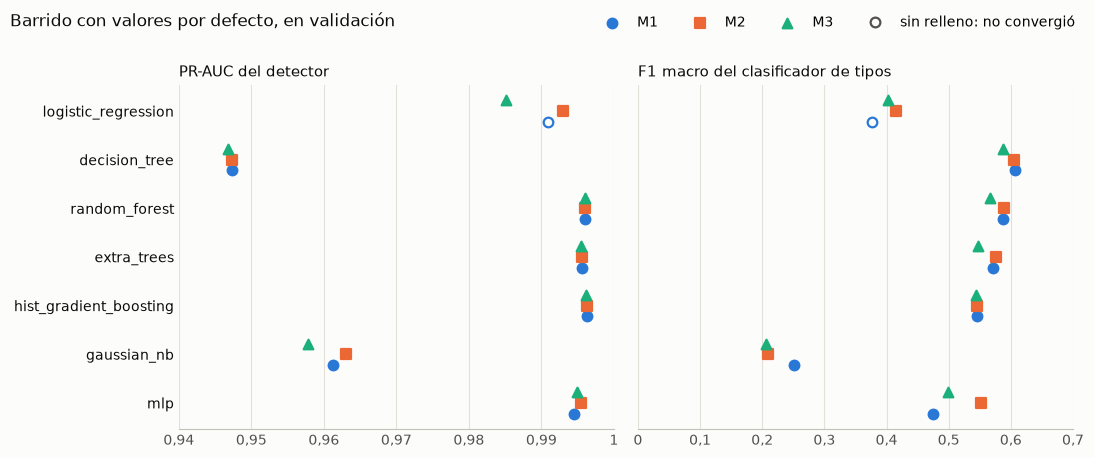

In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Las cifras de las figuras van con coma decimal, como en el resto del proyecto.
decimal_comma = FuncFormatter(lambda value, _: f"{value:g}".replace(".", ","))

METHOD_STYLES = {  # paleta categórica validada (3 colores) y una forma por método
    "m1": {"color": "#2a78d6", "marker": "o"},
    "m2": {"color": "#eb6834", "marker": "s"},
    "m3": {"color": "#1baf7a", "marker": "^"},
}
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plotted = [family for family in MODEL_FAMILIES if family != "dummy"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, facecolor=SURFACE)
panels = [("pr_auc", "PR-AUC del detector", (0.94, 1.0)), ("f1_macro", "F1 macro del clasificador de tipos", (0.0, 0.7))]
for ax, (column, title, limits) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    for offset, (method, style) in zip((-0.22, 0, 0.22), METHOD_STYLES.items()):
        for position, family in enumerate(reversed(plotted)):
            row = summary.loc[(family, method)]
            ax.scatter(
                row[column], position + offset, s=48, marker=style["marker"], color=style["color"],
                facecolor=style["color"] if row["convergió"] else SURFACE, linewidth=1.6, zorder=3,
                label=method.upper() if position == 0 else None,
            )
    ax.set_xlim(*limits)
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
    ax.xaxis.set_major_formatter(decimal_comma)
axes[0].set_yticks(range(len(plotted)), list(reversed(plotted)), color=INK)
handles, labels = axes[1].get_legend_handles_labels()
hollow = Line2D([], [], marker="o", linestyle="", markersize=7, color=MUTED, markerfacecolor=SURFACE, markeredgewidth=1.6)
fig.suptitle("Barrido con valores por defecto, en validación", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.legend([*handles, hollow], [*labels, "sin relleno: no convergió"], ncol=4, frameon=False,
           loc="upper right", bbox_to_anchor=(0.99, 1.0))
fig.savefig(MODEL_SEARCH_DIR / "defaults_scores.png", dpi=200, facecolor=SURFACE)
plt.show()

### Entrenamiento contra validación

El árbol de decisión con sus valores por defecto crece hasta separar todo el entrenamiento: llega a PR-AUC 1 y 0 % de falsas alarmas en entrenamiento, y en validación baja mucho más que Random Forest, que promedia 100 árboles. En el clasificador, el F1 macro de entrenamiento no pasa de unos 0,77 aunque el árbol crezca sin límite, porque los flujos idénticos con tipos distintos (sección 4) no se pueden separar ni siquiera en entrenamiento.

In [12]:
pairs = {"árbol de decisión (M1)": ("decision_tree", "m1"), "Random Forest (M2)": ("random_forest", "m2")}
metrics = [
    ("PR-AUC", "pr_auc_entrenamiento", "pr_auc"),
    ("falsas alarmas", "falsas_alarmas_entrenamiento", "falsas_alarmas"),
    ("F1 macro", "f1_macro_entrenamiento", "f1_macro"),
]
gap = pd.DataFrame(
    [
        {"modelo": name, "métrica": label, "entrenamiento": summary.loc[key, train], "validación": summary.loc[key, val]}
        for name, key in pairs.items()
        for label, train, val in metrics
    ]
)
gap["diferencia"] = gap["validación"] - gap["entrenamiento"]
display(gap.style.format({"entrenamiento": "{:.4f}", "validación": "{:.4f}", "diferencia": "{:+.4f}"}).hide(axis="index"))

modelo,métrica,entrenamiento,validación,diferencia
árbol de decisión (M1),PR-AUC,1.0000,0.9473,-0.0527
árbol de decisión (M1),falsas alarmas,0.0000,0.0858,+0.0858
árbol de decisión (M1),F1 macro,0.7630,0.6062,-0.1568
Random Forest (M2),PR-AUC,1.0000,0.9961,-0.0039
Random Forest (M2),falsas alarmas,0.0014,0.0500,+0.0486
Random Forest (M2),F1 macro,0.7687,0.5886,-0.1801


## 8. Orden de las familias

`select_candidates` elige la mejor combinación de cada familia y ordena las familias con la misma regla:

1. **PR-AUC del detector**: empatan las que quedan a menos de 0,001 de la mejor (`SCORE_TIE_TOLERANCE`, el tercer decimal que muestra la app);
2. entre las empatadas, el **F1 macro del clasificador** del mismo método, con el mismo empate;
3. si siguen empatadas, la **menor tasa de falsas alarmas**.

Dentro de cada familia, el detector y el clasificador usan el mismo método, y solo cuentan las filas que convergieron. `rank` ordena todas las familias; `app_rank`, solo las que pesan menos de 50 MB entre detector y clasificador (`fits_app`).

In [13]:
ranking = select_candidates(results, phases=[1])
display(
    ranking.drop(columns=["detector_params", "classifier_params", "detector_row", "classifier_row"]).style.format(
        {"pr_auc": "{:.4f}", "false_alarm_rate": "{:.1%}", "macro_f1": "{:.3f}", "min_type_f1": "{:.3f}", "model_size_mb": "{:.2f}"},
        na_rep="—",
    ).hide(axis="index")
)

rank,app_rank,family,method,pr_auc,false_alarm_rate,macro_f1,min_type_f1,model_size_mb,fits_app
1,—,random_forest,m2,0.9961,5.0%,0.589,0.225,150.68,False
2,—,extra_trees,m2,0.9956,5.5%,0.576,0.198,439.68,False
3,1,mlp,m2,0.9954,7.0%,0.553,0.110,0.33,True
4,2,hist_gradient_boosting,m1,0.9963,5.5%,0.546,0.080,1.40,True
5,3,logistic_regression,m2,0.9930,9.0%,0.415,0.000,0.03,True
6,4,gaussian_nb,m2,0.9630,26.6%,0.209,0.005,0.03,True
7,5,decision_tree,m1,0.9473,8.6%,0.606,0.213,2.11,True
8,6,dummy,m1,0.6806,100.0%,0.056,0.000,0.02,True


HistGradientBoosting, Random Forest, Extra Trees y MLP empatan en PR-AUC (todas a menos de 0,001 de la mejor), así que las ordena el F1 macro de su clasificador. Por eso HistGradientBoosting, con la PR-AUC más alta, queda después de MLP: su clasificador es el más débil de las cuatro. Random Forest y Extra Trees encabezan el orden, pero con sus valores por defecto pesan más de 50 MB y no podrían ir a la app.

> **Decisión: familias que pasan a la búsqueda de hiperparámetros**
>
> - **Qué se decide:** pasan Random Forest, Extra Trees, HistGradientBoosting y MLP. La regresión logística es el modelo base, con sus valores por defecto y M2. El árbol de decisión, Gaussian NB y dummy quedan como referencia.
> - **Evidencia:** las cuatro familias que pasan empatan en PR-AUC del detector, entre 0,9954 y 0,9963. La regresión logística queda en 0,9930 con 9,0 % de falsas alarmas; Gaussian NB, en 0,9630 con 26,6 %; el árbol de decisión, en 0,9473, porque sin límite de profundidad da probabilidades de 0 o 1.
> - **Alternativas descartadas:** buscar hiperparámetros en las 8 familias, que gasta tiempo en familias sin opción en la regla de selección; quedarse solo con las 3 que hoy caben en la app, que dejaría fuera a Random Forest y Extra Trees, las dos primeras del orden, cuyo tamaño se puede limitar con sus hiperparámetros.
> - **Qué se hace en este notebook:** la búsqueda de hiperparámetros se hace solo con esas cuatro familias; en Random Forest y Extra Trees, la malla incluye parámetros que limitan el tamaño (`max_depth`, `min_samples_leaf`, `n_estimators`).
> - **Dónde se aplica:** en la lista de candidatos de la búsqueda de hiperparámetros y, al final, en los modelos que se exportan.
> - **Valores no vistos:** no aplica; es una decisión sobre modelos, no sobre los datos.

## 9. El experimento de TTL: M2 contra M3

M2 y M3 solo se diferencian en que M3 no usa las tres variables de TTL (`sttl`, `dttl` y `ct_state_ttl`), un atajo conocido del dataset. La tabla muestra, por familia, cuánto cambia cada métrica al quitarlas (M3 − M2); el cambio en falsas alarmas también se da en flujos normales de validación.

In [14]:
m2 = summary.xs("m2", level="método")
m3 = summary.xs("m3", level="método")
fp = detectors["fp"].unstack("requested_method")
ttl = pd.DataFrame(
    {
        "pr_auc": m3["pr_auc"] - m2["pr_auc"],
        "falsas_alarmas_puntos": (m3["falsas_alarmas"] - m2["falsas_alarmas"]) * 100,
        "falsas_alarmas_flujos": fp["m3"] - fp["m2"],
        "f1_macro": m3["f1_macro"] - m2["f1_macro"],
        "f1_peor_tipo": m3["f1_peor_tipo"] - m2["f1_peor_tipo"],
    }
).reindex(MODEL_FAMILIES)
display(
    ttl.style.format(
        {"pr_auc": "{:+.4f}", "falsas_alarmas_puntos": "{:+.2f}", "falsas_alarmas_flujos": "{:+.0f}", "f1_macro": "{:+.3f}", "f1_peor_tipo": "{:+.3f}"}
    )
)

,pr_auc,falsas_alarmas_puntos,falsas_alarmas_flujos,f1_macro,f1_peor_tipo
dummy,+0.0000,+0.00,+0,+0.000,+0.000
logistic_regression,-0.0079,+5.90,+661,-0.012,+0.000
decision_tree,-0.0005,+0.13,+15,-0.018,-0.021
random_forest,-0.0001,+0.34,+38,-0.022,-0.038
extra_trees,-0.0002,+0.26,+29,-0.028,-0.076
hist_gradient_boosting,-0.0001,+0.21,+23,-0.002,-0.049
gaussian_nb,-0.0052,+16.88,+1890,-0.002,-0.003
mlp,-0.0005,+0.40,+45,-0.054,-0.110


La figura une, para cada familia, la tasa de falsas alarmas con M2 (gris) y con M3 (azul). Dummy no aparece: marca todo como alerta con los dos métodos.

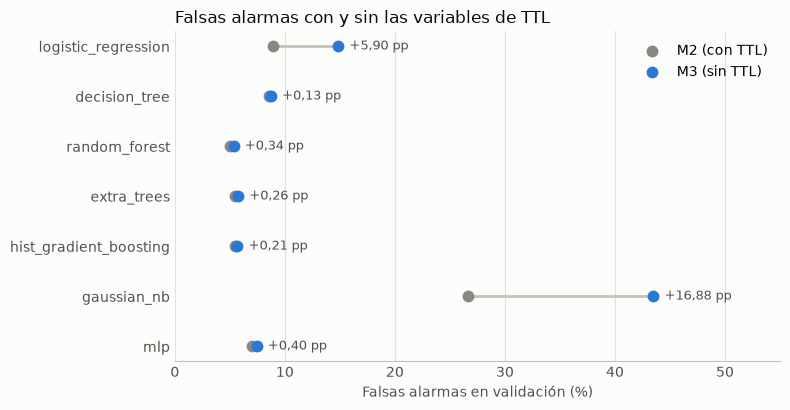

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for position, family in enumerate(reversed(plotted)):
    before, after = m2.loc[family, "falsas_alarmas"] * 100, m3.loc[family, "falsas_alarmas"] * 100
    ax.plot([before, after], [position, position], color=AXIS, linewidth=2, zorder=1)
    ax.scatter(before, position, s=56, color="#898781", zorder=2, label="M2 (con TTL)" if position == 0 else None)
    ax.scatter(after, position, s=56, color="#2a78d6", zorder=3, label="M3 (sin TTL)" if position == 0 else None)
    ax.annotate(f"{after - before:+.2f} pp".replace(".", ","), (max(before, after), position), xytext=(8, 0), textcoords="offset points",
                va="center", color=MUTED, fontsize=9)
ax.set_yticks(range(len(plotted)), list(reversed(plotted)), color=INK)
ax.set_xlabel("Falsas alarmas en validación (%)", color=MUTED)
ax.set_xlim(0, 55)
ax.xaxis.set_major_formatter(decimal_comma)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, loc="upper right")
ax.set_title("Falsas alarmas con y sin las variables de TTL", loc="left", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(MODEL_SEARCH_DIR / "ttl_m2_vs_m3.png", dpi=200, facecolor=SURFACE)
plt.show()

Cómo leerlo:

- En los modelos de árboles y en MLP, quitar el TTL cambia la PR-AUC del detector menos que el empate de 0,001, y sube las falsas alarmas en pocas décimas de punto; el clasificador de tipos sí pierde F1 macro en todas las familias que aprenden (dummy no cambia).
- La regresión logística y Gaussian NB dependen mucho más del TTL: sin él, sus falsas alarmas suben varios puntos.
- Es una comparación en la parte de validación, que sale del mismo archivo que el entrenamiento: mide cuánto usan los modelos el TTL en esa distribución, no si el atajo se sostiene en otros datos. Para los 3 modelos finales, su versión con M3 también se evalúa en prueba, solo para el artículo.

## 10. Búsqueda de hiperparámetros

Las cuatro familias que pasan se buscan con el método que eligió el barrido con valores por defecto (sección 8), con una malla por tarea: el detector y el clasificador tienen sus propios hiperparámetros y sus propios pesos de clase. Los valores están en `PHASE2_GRIDS` (`ml/training.py`); estas son sus razones:

- **Random Forest y Extra Trees.** La documentación de scikit-learn advierte que con los valores por defecto los árboles crecen completos, sin podar, y pueden ser muy grandes, y que para reducir la memoria hay que limitar parámetros como `max_depth` y `min_samples_leaf`. Con los valores por defecto pesaron 150,7 y 439,7 MB (sección 7). La malla prueba `min_samples_leaf` ∈ {1, 5, 10, 20}, `max_depth` ∈ {sin límite, 20} y un tope de 50 o 100 árboles. Pesos de clase: `None` o `"balanced"` en el detector; en el clasificador, también `"balanced_subsample"` en Random Forest. En Extra Trees no va, porque sin bootstrap (su valor por defecto) scikit-learn lo trata igual que `"balanced"`.
- **HistGradientBoosting.** `learning_rate` ∈ {0,05, 0,1} (0,1 es el valor por defecto), `max_leaf_nodes` ∈ {15, 31, 63} (el valor por defecto, la mitad y el doble), `min_samples_leaf` ∈ {20, 100} (el valor por defecto y uno que regulariza) y un tope de 200 iteraciones, porque el detector usó las 100 de su tope en el barrido. Pesos de clase: `None` o `"balanced"`.
- **MLP.** `hidden_layer_sizes` ∈ {(64,), (100,), (100, 50)} (el valor por defecto, una capa más chica y dos capas) y `alpha` ∈ {0,0001; 0,001; 0,01} (el valor por defecto y dos niveles más de regularización L2). MLP no tiene `class_weight`; los pesos balanceados se pasan a `fit` como `sample_weight`.

Son 228 combinaciones. Ya están guardadas, así que esta celda no entrena nada.

In [16]:
from threat_detector.config import MAX_MODEL_SIZE_MB
from threat_detector.ml.training import PHASE2_GRIDS, curve_candidates, phase2_candidates

phase2_methods = {family: ranking.set_index("family").loc[family, "method"] for family in PHASE2_GRIDS}
print("Método de cada familia:", phase2_methods)
results = run_search(phase2_candidates(phase2_methods), training_flows, validation_flows, verbose=True)

Método de cada familia: {'random_forest': 'm2', 'extra_trees': 'm2', 'hist_gradient_boosting': 'm1', 'mlp': 'm2'}
Candidatos: 228; ya guardados: 228; por entrenar: 0.


Resumen de la búsqueda por familia y tarea: cuántas combinaciones, la mejor métrica de validación (PR-AUC del detector o F1 macro del clasificador), el rango de tamaños y los minutos que tomó.

In [17]:
tuned = results[results["phase"] == 2].copy()
tuned["métrica"] = tuned["pr_auc"].fillna(tuned["macro_f1"])
search_summary = tuned.groupby(["family", "task"], sort=False).agg(
    combinaciones=("métrica", "size"),
    mejor_métrica=("métrica", "max"),
    mb_mínimo=("model_size_mb", "min"),
    mb_máximo=("model_size_mb", "max"),
    minutos=("search_seconds", lambda seconds: seconds.sum() / 60),
    convergieron=("converged", "sum"),
)
display(search_summary.style.format({"mejor_métrica": "{:.4f}", "mb_mínimo": "{:.1f}", "mb_máximo": "{:.1f}", "minutos": "{:.1f}"}))

## 11. Orden final de las familias

Con las filas del barrido y de la búsqueda, `select_candidates` da dos órdenes con la misma regla (PR-AUC → F1 macro → falsas alarmas):

- **El mejor posible**, sin mirar el tamaño: el mejor detector y el mejor clasificador de cada familia.
- **El de la app**: con `max_size_mb`, cada familia se elige entre los pares detector + clasificador del mismo método que suman menos de 50 MB, con la regla PR-AUC → F1 macro → falsas alarmas → peor tipo.

Las filas de las curvas de validación (sección 12) no cuentan para elegir.

In [18]:
columns = ["rank", "app_rank", "family", "method", "pr_auc", "false_alarm_rate", "macro_f1", "min_type_f1", "model_size_mb", "fits_app"]
formats = {"pr_auc": "{:.4f}", "false_alarm_rate": "{:.1%}", "macro_f1": "{:.3f}", "min_type_f1": "{:.3f}", "model_size_mb": "{:.2f}"}
best_possible = select_candidates(results, phases=[1, 2])
for_app = select_candidates(results, phases=[1, 2], max_size_mb=MAX_MODEL_SIZE_MB)
print("El mejor posible, sin límite de tamaño:")
display(best_possible[columns].style.format(formats, na_rep="—").hide(axis="index"))
print("Dentro de 50 MB por modelo, para la app:")
display(for_app[columns].style.format(formats, na_rep="—").hide(axis="index"))

El mejor posible, sin límite de tamaño:


rank,app_rank,family,method,pr_auc,false_alarm_rate,macro_f1,min_type_f1,model_size_mb,fits_app
1,—,random_forest,m2,0.9963,4.9%,0.630,0.147,132.52,False
2,1,hist_gradient_boosting,m1,0.9968,4.6%,0.619,0.131,14.22,True
3,—,extra_trees,m2,0.9956,5.3%,0.576,0.198,458.49,False
4,2,mlp,m2,0.9959,6.2%,0.565,0.104,0.39,True
5,3,logistic_regression,m2,0.9930,9.0%,0.415,0.000,0.03,True
6,4,gaussian_nb,m2,0.9630,26.6%,0.209,0.005,0.03,True
7,5,decision_tree,m1,0.9473,8.6%,0.606,0.213,2.11,True
8,6,dummy,m1,0.6806,100.0%,0.056,0.000,0.02,True


Dentro de 50 MB por modelo, para la app:


rank,app_rank,family,method,pr_auc,false_alarm_rate,macro_f1,min_type_f1,model_size_mb,fits_app
1,1,hist_gradient_boosting,m1,0.9968,4.6%,0.619,0.131,14.22,True
2,2,random_forest,m2,0.9964,5.3%,0.603,0.133,43.68,True
3,3,mlp,m2,0.9959,6.2%,0.565,0.104,0.39,True
4,4,extra_trees,m2,0.9962,5.7%,0.531,0.098,36.98,True
5,5,logistic_regression,m2,0.9930,9.0%,0.415,0.000,0.03,True
6,6,gaussian_nb,m2,0.9630,26.6%,0.209,0.005,0.03,True
7,7,decision_tree,m1,0.9473,8.6%,0.606,0.213,2.11,True
8,8,dummy,m1,0.6806,100.0%,0.056,0.000,0.02,True


Los hiperparámetros elegidos para la app, con el tamaño que eligió el crecimiento por bloques (`best_iteration`), el tamaño en MB y las métricas de entrenamiento junto a las de validación. Al final, el tamaño total de los 3 primeros: la app los carga juntos en memoria.

In [19]:
chosen = []
for choice in for_app.dropna(subset=["method"]).itertuples():
    for task, row in (("detector", choice.detector_row), ("tipos", choice.classifier_row)):
        result = results.loc[row]
        is_detector = task == "detector"
        chosen.append({
            "familia": choice.family,
            "tarea": task,
            "fase": result["phase"],
            "params": result["params"],
            "best_iteration": result["best_iteration"],
            "mb": result["model_size_mb"],
            "entrenamiento": result["train_pr_auc"] if is_detector else result["train_macro_f1"],
            "validación": result["pr_auc"] if is_detector else result["macro_f1"],
        })
chosen = pd.DataFrame(chosen)
chosen["diferencia"] = chosen["validación"] - chosen["entrenamiento"]
with pd.option_context("display.max_colwidth", None):
    display(
        chosen.style.format(
            {"best_iteration": "{:.0f}", "mb": "{:.1f}", "entrenamiento": "{:.4f}", "validación": "{:.4f}", "diferencia": "{:+.4f}"},
            na_rep="—",
        ).hide(axis="index")
    )

app_models = for_app[for_app["app_rank"] <= 3]
print(f"Los 3 de la app: {', '.join(app_models['family'])}")
print(f"Tamaño total en memoria: {app_models['model_size_mb'].sum():.1f} MB")

familia,tarea,fase,params,best_iteration,mb,entrenamiento,validación,diferencia
hist_gradient_boosting,detector,2,"{""model__class_weight"": null, ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 20}",180,1.3,0.9989,0.9968,-0.0021
hist_gradient_boosting,tipos,2,"{""model__class_weight"": ""balanced"", ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 100}",200,12.9,0.7123,0.6185,-0.0938
random_forest,detector,2,"{""model__class_weight"": ""balanced"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 5, ""model__n_estimators"": 50}",50,12.2,0.9986,0.9964,-0.0023
random_forest,tipos,2,"{""model__class_weight"": ""balanced"", ""model__max_depth"": null, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}",25,31.5,0.7020,0.6028,-0.0993
mlp,detector,2,"{""model__alpha"": 0.001, ""model__hidden_layer_sizes"": [100, 50], ""sample_weight"": ""balanced""}",68,0.3,0.9969,0.9959,-0.0010
mlp,tipos,2,"{""model__alpha"": 0.001, ""model__hidden_layer_sizes"": [64], ""sample_weight"": null}",93,0.1,0.5604,0.5649,+0.0045
extra_trees,detector,2,"{""model__class_weight"": ""balanced"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}",50,21.5,0.9983,0.9962,-0.0021
extra_trees,tipos,2,"{""model__class_weight"": null, ""model__max_depth"": null, ""model__min_samples_leaf"": 5, ""model__n_estimators"": 50}",25,15.5,0.5509,0.5309,-0.0200
logistic_regression,detector,1,{},138,0.0,0.9928,0.9930,+0.0002
logistic_regression,tipos,1,{},477,0.0,0.4189,0.4145,-0.0044


Los 3 de la app: hist_gradient_boosting, random_forest, mlp
Tamaño total en memoria: 58.3 MB


Cómo leer los dos órdenes:

- **Sin límite**, Random Forest queda primero (su clasificador llega a F1 macro 0,630), pero pesa 132,5 MB; Extra Trees, tercero, pesa 458,5 MB.
- **Dentro de 50 MB**, HistGradientBoosting queda primero: tiene la mejor PR-AUC (0,9968), la menor tasa de falsas alarmas (4,6 %) y su clasificador balanceado llega a F1 macro 0,619, con 14,2 MB. Random Forest queda segundo con un par de 43,7 MB y MLP tercero; Extra Trees baja al cuarto lugar, porque su mejor clasificador sin límite pesaba 237,7 MB y el que cabe tiene F1 macro 0,531.
- Los clasificadores elegidos de HistGradientBoosting y Random Forest usan pesos balanceados; en los detectores, HistGradientBoosting eligió uno sin pesos y Random Forest, Extra Trees y MLP, uno con pesos.
- El clasificador de HistGradientBoosting usó las 200 iteraciones de su tope: su F1 macro todavía no había dejado de subir dentro de la malla.

## 12. Curvas de validación

Cada curva parte de la combinación elegida para la app (sección 11) y varía un solo parámetro, con la métrica de entrenamiento (gris) y la de validación (azul) en la misma gráfica. Si la de entrenamiento sigue subiendo y la de validación se queda quieta o baja, el modelo está aprendiendo detalles del entrenamiento que no le sirven en datos nuevos. La línea punteada marca el valor elegido.

Las filas de las curvas llevan `phase = "curve"` y no cuentan para elegir. Ya están guardadas, así que esta celda no entrena nada.

In [20]:
curves = curve_candidates(results, for_app)
results = run_search(curves, training_flows, validation_flows, verbose=True)
curve_rows = results[results["phase"] == CURVE_PHASE]

Candidatos: 68; ya guardados: 68; por entrenar: 0.


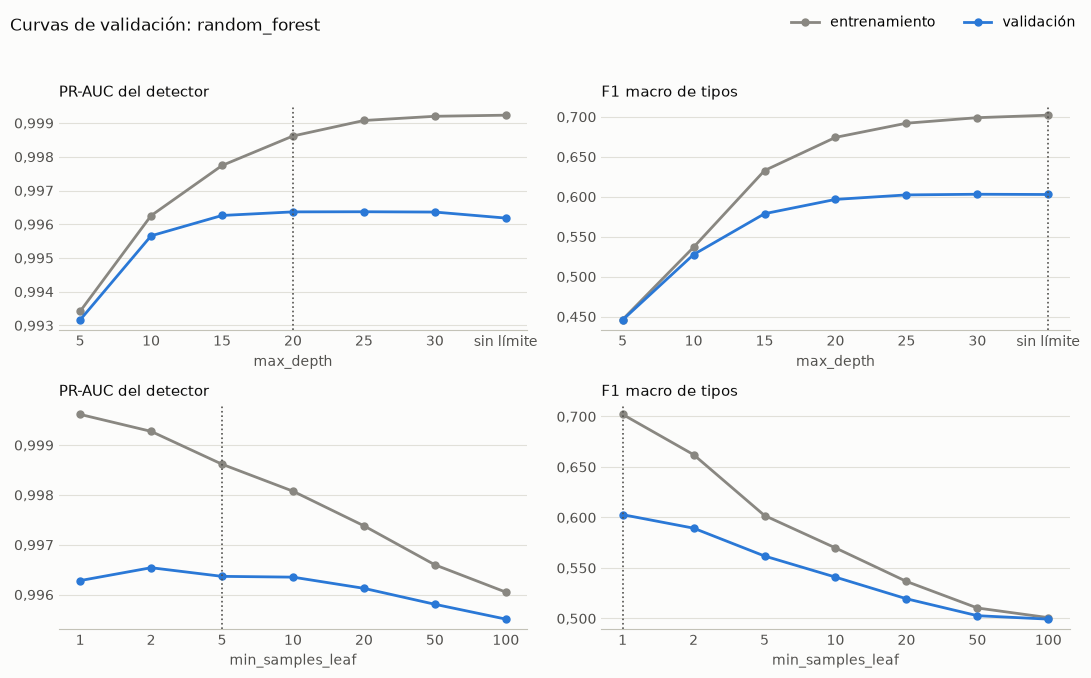

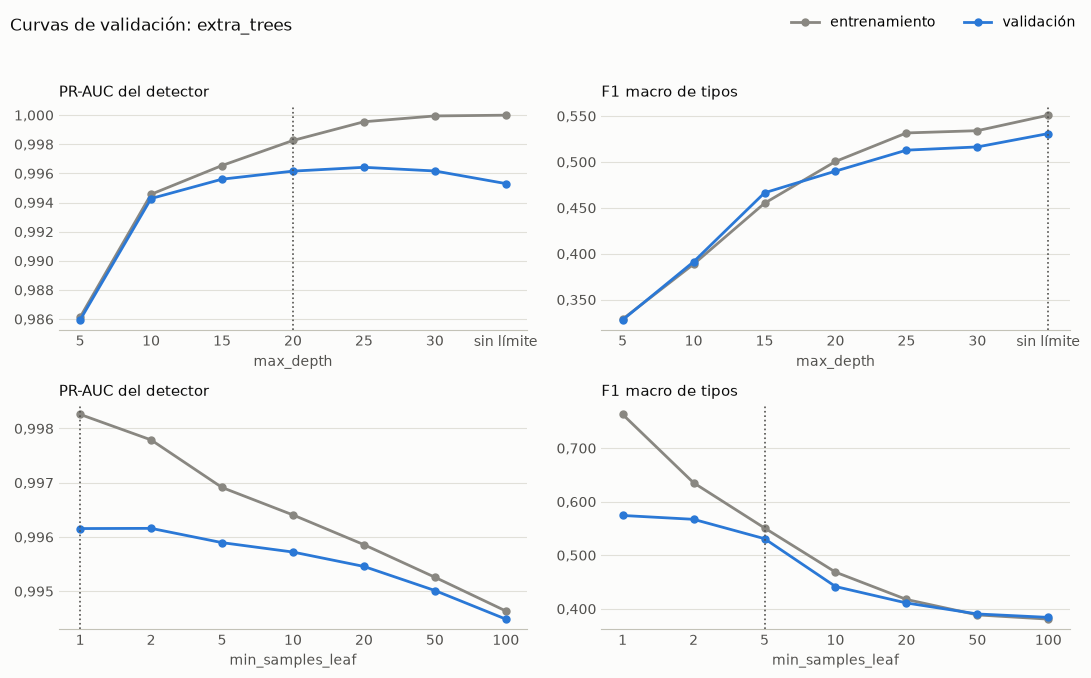

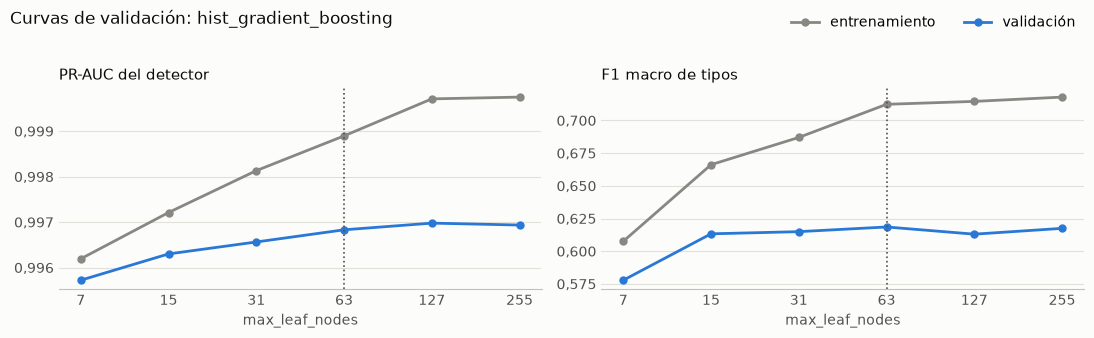

In [21]:
import json

TRAIN_COLOR, VALIDATION_COLOR = "#898781", "#2a78d6"
TASK_METRICS = {"detector": ("pr_auc", "train_pr_auc", "PR-AUC del detector"), "attack_type": ("macro_f1", "train_macro_f1", "F1 macro de tipos")}
PARAM_LABELS = {"model__max_depth": "max_depth", "model__min_samples_leaf": "min_samples_leaf", "model__max_leaf_nodes": "max_leaf_nodes"}


def curve_points(family, task, name):
    """Valores del parámetro y métricas de su curva, en el orden de CURVE_PARAMS."""
    base = json.loads(results.loc[for_app.set_index("family").loc[family, "detector_row" if task == "detector" else "classifier_row"], "params"])
    rows = curve_rows[(curve_rows["family"] == family) & (curve_rows["task"] == task)]
    validation, train = TASK_METRICS[task][:2]
    points = []
    for value in CURVE_PARAMS[family][name]:
        match = rows[rows["params"] == json.dumps({**base, name: value}, sort_keys=True)].iloc[0]
        points.append((value, match[train], match[validation]))
    return base.get(name), points


def plot_curves(family):
    names = list(CURVE_PARAMS[family])
    fig, axes = plt.subplots(len(names), 2, figsize=(11, 3.4 * len(names)), facecolor=SURFACE, squeeze=False)
    for row_axes, name in zip(axes, names):
        for ax, task in zip(row_axes, TASK_METRICS):
            chosen_value, points = curve_points(family, task, name)
            labels = ["sin límite" if value is None else str(value) for value, _, _ in points]
            positions = range(len(points))
            ax.set_facecolor(SURFACE)
            ax.plot(positions, [p[1] for p in points], color=TRAIN_COLOR, linewidth=2, marker="o", markersize=5, label="entrenamiento")
            ax.plot(positions, [p[2] for p in points], color=VALIDATION_COLOR, linewidth=2, marker="o", markersize=5, label="validación")
            ax.axvline(labels.index("sin límite" if chosen_value is None else str(chosen_value)), color=MUTED, linestyle=":", linewidth=1.2)
            ax.set_xticks(list(positions), labels)
            ax.set_xlabel(PARAM_LABELS[name], color=MUTED)
            ax.set_title(TASK_METRICS[task][2], loc="left", color=INK, fontsize=11)
            ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.3f}".replace(".", ",")))
            ax.grid(axis="y", color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(AXIS)
            ax.tick_params(colors=MUTED, length=0)
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.suptitle(f"Curvas de validación: {family}", x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.legend(handles, labels, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    fig.savefig(MODEL_SEARCH_DIR / f"curves_{family}.png", dpi=200, facecolor=SURFACE)
    plt.show()


for family in CURVE_PARAMS:
    plot_curves(family)

Cómo leer las curvas:

- **Detectores.** En Random Forest, desde `max_depth` 15 la PR-AUC de validación queda entre 0,9962 y 0,9964 mientras la de entrenamiento sube de 0,9977 a 0,9992: los árboles más profundos no detectan mejor, solo pesan más. En Extra Trees, la de validación llega a su máximo con `max_depth` 25 (0,9964) y baja sin límite de profundidad (0,9953), mientras la de entrenamiento llega a 1,0000.
- **Clasificadores de tipos.** La distancia entre entrenamiento y validación es mayor. En Random Forest y HistGradientBoosting, el F1 macro de entrenamiento llega a 0,70–0,72 y el de validación a 0,60–0,62. En Extra Trees, el clasificador que cabe en 50 MB usa `min_samples_leaf` = 5 (entrenamiento 0,551, validación 0,531); con 1 llegaría a 0,574 en validación, pero pesaría 158,1 MB. Los flujos idénticos con tipos distintos (sección 4) ponen un techo a todos.
- **HistGradientBoosting.** Con más de 63 hojas, la validación ya no mejora en el clasificador y en el detector sube menos que el empate; el entrenamiento sigue subiendo.

## 13. Sobreentrenamiento y regla de simplicidad

Para no elegir un modelo más complejo de lo necesario, después de `select_candidates` se aplica la **regla de simplicidad** (`apply_simplicity_rule`), solo con validación: dentro de la misma familia, método y tarea, si una combinación más simple empata con la elegida, se usa la más simple.

- **Más simple:** no es más compleja en ninguna dimensión y es más simple en al menos una. Random Forest y Extra Trees: menor `max_depth`, mayor `min_samples_leaf`, menos árboles usados. HistGradientBoosting: menos `max_leaf_nodes`, mayor `min_samples_leaf`, menos iteraciones. MLP: menos neuronas o capas, mayor `alpha`.
- **Empate:** detector, PR-AUC a menos de 0,001 y falsas alarmas no peores; clasificador, F1 macro a menos de 0,001. Si hay varias, la de menor tamaño; el par debe seguir por debajo de 50 MB.
- **Filas que cuentan:** las del barrido, la búsqueda y también las curvas, porque la regla solo puede elegir algo más simple que empata, nunca algo con mejor puntaje.

Que un modelo llegue a 1,0 en entrenamiento no lo descarta por sí solo: lo que cuenta es la validación.

In [22]:
from threat_detector.ml.training import apply_simplicity_rule

final = apply_simplicity_rule(results, for_app, max_size_mb=MAX_MODEL_SIZE_MB)
changes = []
for before, after in zip(for_app.itertuples(), final.itertuples()):
    for task, row_before, row_after in (("detector", before.detector_row, after.detector_row), ("tipos", before.classifier_row, after.classifier_row)):
        if row_before != row_after:
            changes.append({
                "familia": after.family, "tarea": task,
                "antes": results.loc[row_before, "params"], "después": results.loc[row_after, "params"],
                "métrica_antes": results.loc[row_before, "pr_auc" if task == "detector" else "macro_f1"],
                "métrica_después": results.loc[row_after, "pr_auc" if task == "detector" else "macro_f1"],
                "mb_antes": results.loc[row_before, "model_size_mb"], "mb_después": results.loc[row_after, "model_size_mb"],
            })
print(f"Combinaciones que cambia la regla: {len(changes)}")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(changes).style.format({"métrica_antes": "{:.4f}", "métrica_después": "{:.4f}", "mb_antes": "{:.1f}", "mb_después": "{:.1f}"}).hide(axis="index"))
app_models = final[final["app_rank"] <= 3]
print(f"Los 3 de la app: {', '.join(app_models['family'])}; tamaño total en memoria: {app_models['model_size_mb'].sum():.1f} MB")

Combinaciones que cambia la regla: 1


familia,tarea,antes,después,métrica_antes,métrica_después,mb_antes,mb_después
random_forest,tipos,"{""model__class_weight"": ""balanced"", ""model__max_depth"": null, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}","{""model__class_weight"": ""balanced"", ""model__max_depth"": 30, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}",0.6028,0.6031,31.5,31.2


Los 3 de la app: hist_gradient_boosting, random_forest, mlp; tamaño total en memoria: 58.0 MB


La regla cambia una sola combinación: el clasificador de tipos de Random Forest pasa de árboles sin límite de profundidad a `max_depth` 30, con el mismo F1 macro dentro del empate y un poco menos de tamaño.

### Brecha entre entrenamiento y validación

Para el artículo: la brecha de los 4 modelos que se registran (los 3 elegidos y el modelo base) y de casos de la búsqueda que sí sobreentrenan. En el detector, la PR-AUC y las falsas alarmas (en entrenamiento, con el umbral de validación); en el clasificador, el F1 macro. Se guarda en `train_validation_gap.csv` y `train_validation_gap.png`.

In [23]:
def defaults_row(family, method, task):
    """Índice de la fila del barrido con valores por defecto de una familia, método y tarea."""
    rows = results[(results["phase"] == 1) & (results["family"] == family) & (results["requested_method"] == method) & (results["task"] == task)]
    return rows.index[0]


final_by_family = final.set_index("family")
cases = []
for family, label in (
    ("hist_gradient_boosting", "registrado"), ("random_forest", "registrado"), ("mlp", "registrado"),
    ("logistic_regression", "modelo base"),
):
    name = f"{family} (modelo base)" if label == "modelo base" else f"{family} (elegido)"
    cases.append((name, label, final_by_family.loc[family, "detector_row"], final_by_family.loc[family, "classifier_row"]))
for family, method in (("decision_tree", "m1"), ("random_forest", "m2"), ("extra_trees", "m2")):
    cases.append((f"{family} por defecto", "sobreentrenado", defaults_row(family, method, "detector"), defaults_row(family, method, "attack_type")))
# El detector de Extra Trees de la curva de max_depth, sin límite de profundidad.
et_base = json.loads(results.loc[final_by_family.loc["extra_trees", "detector_row"], "params"])
et_unlimited = curve_rows[(curve_rows["family"] == "extra_trees") & (curve_rows["task"] == "detector")
                          & (curve_rows["params"] == json.dumps({**et_base, "model__max_depth": None}, sort_keys=True))].index[0]
cases.append(("extra_trees sin límite de profundidad", "sobreentrenado", et_unlimited, None))

gap_rows = []
for name, kind, detector_row, classifier_row in cases:
    measures = [("detector", detector_row, "PR-AUC", "train_pr_auc", "pr_auc"),
                ("detector", detector_row, "falsas alarmas", "train_false_alarm_rate", "false_alarm_rate"),
                ("tipos", classifier_row, "F1 macro", "train_macro_f1", "macro_f1")]
    for task, row, metric, train, validation in measures:
        if row is None:
            continue
        result = results.loc[row]
        gap_rows.append({
            "modelo": name, "caso": kind, "tarea": task, "métrica": metric, "fase": result["phase"],
            "params": result["params"], "entrenamiento": result[train], "validación": result[validation],
            "brecha": result[validation] - result[train],
        })
gap = pd.DataFrame(gap_rows)
gap.to_csv(MODEL_SEARCH_DIR / "train_validation_gap.csv", index=False)
with pd.option_context("display.max_colwidth", 60):
    display(gap.drop(columns="params").style.format({"entrenamiento": "{:.4f}", "validación": "{:.4f}", "brecha": "{:+.4f}"}).hide(axis="index"))

modelo,caso,tarea,métrica,fase,entrenamiento,validación,brecha
hist_gradient_boosting (elegido),registrado,detector,PR-AUC,2,0.9989,0.9968,-0.0021
hist_gradient_boosting (elegido),registrado,detector,falsas alarmas,2,0.0190,0.0462,+0.0272
hist_gradient_boosting (elegido),registrado,tipos,F1 macro,2,0.7123,0.6185,-0.0938
random_forest (elegido),registrado,detector,PR-AUC,2,0.9986,0.9964,-0.0023
random_forest (elegido),registrado,detector,falsas alarmas,2,0.0249,0.0526,+0.0277
random_forest (elegido),registrado,tipos,F1 macro,curve,0.6989,0.6031,-0.0958
mlp (elegido),registrado,detector,PR-AUC,2,0.9969,0.9959,-0.0010
mlp (elegido),registrado,detector,falsas alarmas,2,0.0509,0.0623,+0.0114
mlp (elegido),registrado,tipos,F1 macro,2,0.5604,0.5649,+0.0045
logistic_regression (modelo base),modelo base,detector,PR-AUC,1,0.9928,0.9930,+0.0002


La figura muestra la brecha (validación − entrenamiento) en PR-AUC del detector y en F1 macro del clasificador. Una barra hacia la izquierda es un modelo que rinde peor con datos que no vio que con los de entrenamiento. Azul: los modelos que se registran; gris: casos de la búsqueda.

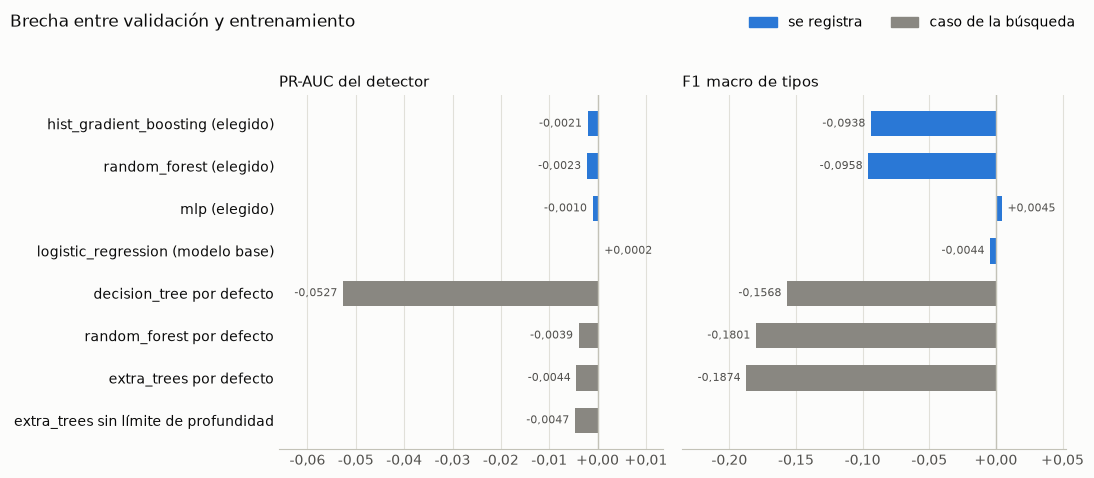

In [24]:
from matplotlib.patches import Patch

REGISTERED, SEARCH_CASE = "#2a78d6", "#898781"
panels = [("PR-AUC", "PR-AUC del detector"), ("F1 macro", "F1 macro de tipos")]
names = [case[0] for case in cases]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True, facecolor=SURFACE)
for ax, (metric, title) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    subset = gap[gap["métrica"] == metric].set_index("modelo")
    for position, name in enumerate(reversed(names)):
        if name not in subset.index:
            continue
        value = subset.loc[name, "brecha"]
        color = SEARCH_CASE if subset.loc[name, "caso"] == "sobreentrenado" else REGISTERED
        ax.barh(position, value, color=color, height=0.6)
        ax.annotate(f"{value:+.4f}".replace(".", ","), (value, position), xytext=(-4 if value < 0 else 4, 0),
                    textcoords="offset points", ha="right" if value < 0 else "left", va="center", color=MUTED, fontsize=8)
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:+.2f}".replace(".", ",")))
    ax.margins(x=0.25)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
axes[0].set_yticks(range(len(names)), list(reversed(names)), color=INK)
fig.suptitle("Brecha entre validación y entrenamiento", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend([Patch(color=REGISTERED), Patch(color=SEARCH_CASE)], ["se registra", "caso de la búsqueda"],
           ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
fig.savefig(MODEL_SEARCH_DIR / "train_validation_gap.png", dpi=200, facecolor=SURFACE)
plt.show()

## 14. Cierre

Resumen de la búsqueda, toda con la parte de validación:

- **Barrido con valores por defecto:** 8 familias × 3 métodos × 2 tareas (48 combinaciones). En ninguna familia ganó M3; pasaron a la búsqueda de hiperparámetros las 4 familias que empataron en PR-AUC del detector (HistGradientBoosting, Random Forest, Extra Trees y MLP). La regresión logística quedó como modelo base y el árbol de decisión, Gaussian NB y dummy como referencia.
- **Búsqueda de hiperparámetros:** 228 combinaciones de esas 4 familias, cada una con su método, más 64 filas de curvas de validación.
- **Elección:** dentro de 50 MB por modelo, con la regla PR-AUC → F1 macro → falsas alarmas → peor tipo, y después la regla de simplicidad, que solo cambió el clasificador de Random Forest (`max_depth` 30 en vez de sin límite). Los 3 elegidos son HistGradientBoosting (M1; PR-AUC 0,9968, F1 macro 0,619), Random Forest (M2; 0,9964 y 0,603) y MLP (M2; 0,9959 y 0,565); juntos pesan 58,0 MB.
- **Límite:** el clasificador de HistGradientBoosting usó las 200 iteraciones del tope de su malla; no se sabe si mejoraría con más.

Las decisiones están anotadas en `CLAUDE.md` y se tomaron antes de usar la prueba. El entrenamiento final, la evaluación en la partición de prueba y el registro de los modelos en la app están en `notebooks/06_final_training.ipynb`.